# Tutorial on Forecasting Ozone with RNNs

This hands-on tutorial accompanies the [Recurrent Neural Networks](../lectures_ML/DeepLearning/rnn.ipynb) notes. We train two recurrent networks, a simple RNN and an LSTM, to predict a day's ozone in Washington, DC from the ozone and weather of the days before it.

Ground-level ozone is a secondary pollutant. It forms when nitrogen oxides and volatile organic compounds react in sunlight, so it is highest on hot, sunny, stagnant days, and an episode can build over several days as the air sits still. The data are the county file from the Week 6 tutorial: the daily maximum 8-hour average ozone (MDA8, in ppb), the standard the EPA regulates, with that day's maximum temperature, wind speed, and relative humidity, from EPA's Air Quality System.

Each sample is a window of 30 days. For each day the inputs are the previous day's ozone and that day's weather, and the target is the ozone on the window's last day. That is the **sequence-to-vector** setup from the notes. Using the weather of the target day is what an operational ozone forecast does: tomorrow's ozone is predicted from a weather forecast for tomorrow and the ozone measured so far.

```{note}
The data file is in the class data folder on Chopin, the same file as in Week 6. If you are working elsewhere, `ozone_county_daily.csv.gz` is in the `tutorials` folder of the course repository. Training both networks takes about a minute on a CPU.
```

In [1]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
from tensorflow import keras
from tensorflow.keras.layers import Input, SimpleRNN, LSTM, Dense

## The data

We read the file with the dates as the index and keep one county, Washington, DC, which has a measurement on every day from January 2019 to December 2023. The columns we use are `ozone` (MDA8, ppb), `ozone_yesterday` (the previous day's MDA8), `tmax` (°F), `wind` (knots), and `rh` (%).

In [2]:
df = pd.read_csv("/data9/CLMT5120/data/shr/ozone_county_daily.csv.gz", index_col="date", parse_dates=True)
o3 = df[df.county == "District of Columbia"]
o3

,state,county,fips,lat,lon,ozone,ozone_yesterday,tmax,wind,wind_dir,rh
date,,,,,,,,,,,
2019-01-02,District Of Columbia,District of Columbia,11001,38.897,-76.984,17.7,19.5,46.2,6.1,143.0,62.7
2019-01-03,District Of Columbia,District of Columbia,11001,38.897,-76.984,17.0,17.7,48.4,7.1,204.0,62.6
2019-01-04,District Of Columbia,District of Columbia,11001,38.897,-76.984,12.0,17.0,49.1,5.7,145.0,76.2
2019-01-05,District Of Columbia,District of Columbia,11001,38.897,-76.984,17.3,12.0,52.7,10.0,250.0,77.0
2019-01-06,District Of Columbia,District of Columbia,11001,38.897,-76.984,26.0,17.3,53.5,9.5,229.0,50.7
...,...,...,...,...,...,...,...,...,...,...,...
2023-12-27,District Of Columbia,District of Columbia,11001,38.900,-76.988,21.7,21.3,54.8,3.9,59.0,91.0
2023-12-28,District Of Columbia,District of Columbia,11001,38.900,-76.988,22.7,21.7,57.6,3.6,259.0,80.6
2023-12-29,District Of Columbia,District of Columbia,11001,38.900,-76.988,26.7,22.7,53.0,4.6,298.0,53.0


Ozone (top, ppb) and maximum temperature (bottom, °F) for the summer of 2023. Ozone rises and falls with the temperature, and high days come in runs of several days.

array([<Axes: xlabel='date'>, <Axes: xlabel='date'>], dtype=object)

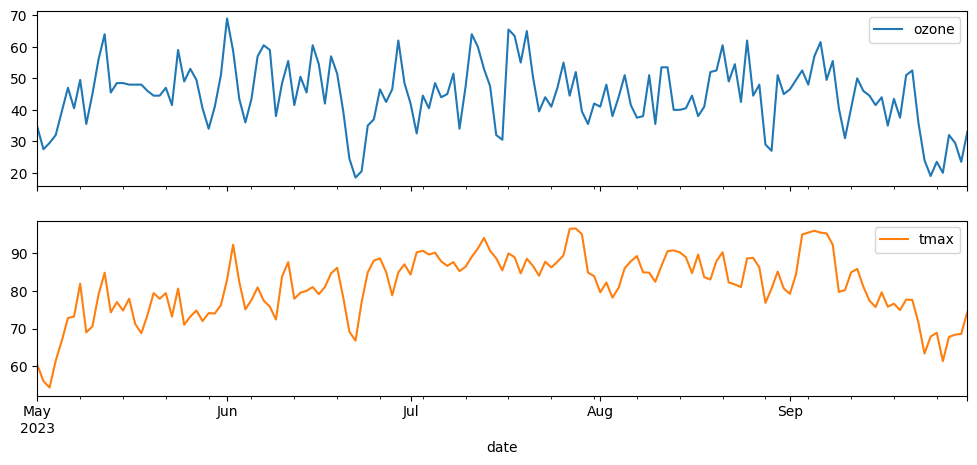

In [3]:
o3[["ozone", "tmax"]]["2023-05":"2023-09"].plot(subplots=True, figsize=(12, 5))

## Split by time, then scale

We train on 2019 to 2021, validate on 2022, and test on 2023. The inputs are standardized with the training period's mean and standard deviation. The target stays in ppb.

In [4]:
features = ["ozone_yesterday", "tmax", "wind", "rh"]
train, valid, test = o3.loc["2019":"2021"], o3.loc["2022"], o3.loc["2023"]
scaler = StandardScaler().fit(train[features])

## Windows: 30 days per sample

A recurrent layer takes samples of shape (time steps, features). We slide a 30-day window along each period, one day at a time. Each window is one sample, and its target is the ozone on the window's last day. The first 29 days of each period serve only as history.

In [5]:
seq_len = 30

def windows(d):
    x = scaler.transform(d[features])
    X = np.stack([x[i:i + seq_len] for i in range(len(d) - seq_len + 1)])
    return X, d["ozone"].values[seq_len - 1:]

X_train, y_train = windows(train)
X_valid, y_valid = windows(valid)
X_test, y_test = windows(test)
print(X_train.shape, X_valid.shape, X_test.shape)

(1066, 30, 4) (336, 30, 4) (336, 30, 4)


## Two baselines

We collect the test predictions in one table, starting with two baselines that need no training:

- **Persistence**: today's ozone equals yesterday's.
- **Climatology**: the 2019 to 2021 average ozone for that month.

The scores come at the end, as R²: 1 is perfect, and 0 is no better than always predicting the mean.

In [6]:
pred = pd.DataFrame({"observed": y_test}, index=test.index[seq_len - 1:])
pred["persistence"] = test.ozone_yesterday[seq_len - 1:]
pred["climatology"] = train.groupby(train.index.month).ozone.mean()[pred.index.month].values

## A simple RNN

The two networks differ by one word, so we write the steps once, in a function that takes the recurrent layer as its argument. It builds the network (10 neurons, then a `Dense` layer for the ozone value), prints its summary, and trains it with early stopping.

`SimpleRNN(10)` is a recurrent layer of 10 neurons. At each time step it combines that day's 4 inputs with its own 10 outputs from the day before, using the same weights every day. Only its output on the last day goes on to the `Dense` layer, which turns it into one ozone value. The summary shows 161 weights: 4 × 10 for the inputs, 10 × 10 for the connections from the previous day, 10 biases, and 11 in the `Dense` layer. The count does not depend on the length of the sequence.

We raise Adam's learning rate from its default of 0.001 to 0.01. Here it trains faster and gives the same result from different random starts.

In [7]:
def fit_model(layer):
    keras.utils.set_random_seed(42)
    model = keras.Sequential([Input(shape=(seq_len, 4)), layer(10), Dense(1)])
    model.compile(loss="mse", optimizer=keras.optimizers.Adam(0.01))
    model.summary()
    early_stop = keras.callbacks.EarlyStopping(patience=20, restore_best_weights=True)
    model.fit(X_train, y_train, epochs=300, validation_data=(X_valid, y_valid), callbacks=[early_stop])
    return model

In [8]:
rnn = fit_model(SimpleRNN)

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 simple_rnn (SimpleRNN)      (None, 10)                150       
                                                                 
 dense (Dense)               (None, 1)                 11        
                                                                 
Total params: 161
Trainable params: 161
Non-trainable params: 0
_________________________________________________________________
Epoch 1/300
34/34 [==============================] - 0s 4ms/step - loss: 1399.1217 - val_loss: 1168.0596
Epoch 2/300
34/34 [==============================] - 0s 1ms/step - loss: 1011.0303 - val_loss: 869.7097
Epoch 3/300
34/34 [==============================] - 0s 1ms/step - loss: 766.9867 - val_loss: 673.6434
Epoch 4/300
34/34 [==============================] - 0s 1ms/step - loss: 600.3451 - val_loss: 536.4894
Epoch 5/300
34/34 [====================

## An LSTM

The same model with `LSTM` in place of `SimpleRNN`. The LSTM carries a second state, the cell state, which its gates can keep almost unchanged from step to step. It has 611 weights: the three gates and the candidate update each have the simple RNN's 150, so 4 × 150 = 600, plus the same 11 in the `Dense` layer.

In [9]:
lstm = fit_model(LSTM)

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 (None, 10)                600       
                                                                 
 dense_1 (Dense)             (None, 1)                 11        
                                                                 
Total params: 611
Trainable params: 611
Non-trainable params: 0
_________________________________________________________________
Epoch 1/300
34/34 [==============================] - 1s 12ms/step - loss: 1364.9802 - val_loss: 1123.8395
Epoch 2/300
34/34 [==============================] - 0s 4ms/step - loss: 973.9788 - val_loss: 844.6393
Epoch 3/300
34/34 [==============================] - 0s 3ms/step - loss: 744.5841 - val_loss: 654.5720
Epoch 4/300
34/34 [==============================] - 0s 3ms/step - loss: 579.5007 - val_loss: 513.1360
Epoch 5/300
34/34 [==================

## Evaluate on the test year

The networks' predictions join the baselines in the table, and each column gets its R² against the observations (the `observed` column scores 1 against itself).

In [10]:
pred["RNN"] = rnn.predict(X_test)[:, 0]
pred["LSTM"] = lstm.predict(X_test)[:, 0]
for c in pred:
    print(c, round(r2_score(pred.observed, pred[c]), 2))

11/11 [==============================] - 0s 709us/step
observed 1.0
persistence 0.43
climatology 0.41
RNN 0.74
LSTM 0.75


Observed and predicted ozone (ppb) for the summer of 2023. Persistence is always one day late: it repeats yesterday, so it misses every rise and every fall. The networks see the day's weather and the days before it.

<Axes: xlabel='date'>

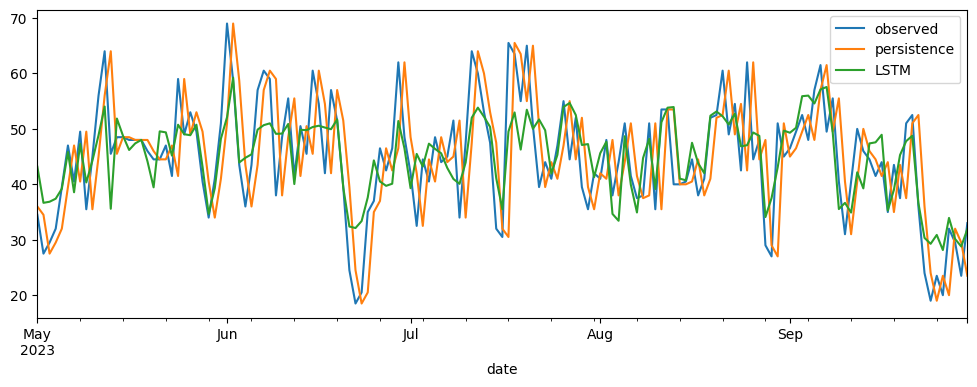

In [11]:
pred[["observed", "persistence", "LSTM"]]["2023-05":"2023-09"].plot(figsize=(12, 4))

### Try it yourself

1. **A GRU.** Import `GRU` from `tensorflow.keras.layers`, run `gru = fit_model(GRU)`, and add its predictions to the table. How many weights does it have, and how does it score? (Keras counts a few more weights than the formula in the notes, because by default it gives the GRU a second set of biases.)
2. **Window length.** Try `seq_len = 7` and `seq_len = 90`. Rebuild the windows and the baseline table, and train the LSTM again. How much history does ozone need?
3. **Seeds.** Change the seed in `fit_model` from 42 to 0 and train both networks again. How much do the scores change? Is the gap between the networks larger than the change from the seed?
4. **Without yesterday's ozone.** Remove `"ozone_yesterday"` from `features` and change `4` to `3` in `fit_model`. Can the networks still beat persistence from the weather alone?
5. **Another county.** The file has 172 counties. Pick one with a complete record, for example `"Harris"` (Houston) or `"Los Angeles"`, and compare its persistence score with this one.